# Saeed Elhami Rad

# Real-Time ASL Alphabet Recognition and Word Formation

## Project Overview

This project recognizes American Sign Language (ASL) alphabet gestures using a webcam and machine learning.

The system extracts hand landmarks using MediaPipe, classifies hand gestures using an SVM model, and combines recognized letters to form words.

**Technologies:** Python, OpenCV, MediaPipe, NumPy, Scikit-learn, Joblib

**Model:** Support Vector Machine (SVM)

### Import Libraries

Importing the required Python libraries for image processing, hand landmark extraction, machine learning, model evaluation, visualization, and model saving.

In [1]:
import cv2
import numpy as np
import pandas as pd
import time
import mediapipe as mp
import matplotlib.pyplot as plt
import joblib
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix,ConfusionMatrixDisplay

### Dataset Configuration

Defining the dataset path and the list of ASL alphabet classes used in the project.

In [2]:
dataset_path = Path(r"asl_alphabet_train")

if not dataset_path.exists():
    raise FileNotFoundError(f"Dataset path not found: {dataset_path}")

classes = sorted(folder.name for folder in dataset_path.iterdir() if folder.is_dir())

print("Number of classes:", len(classes))
print("Classes:", classes)

Number of classes: 29
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


### Dataset Overview and Class Distribution

Checking the number of images available in each class to understand the dataset structure and class distribution.

In [3]:
image_extensions = {".jpg", ".jpeg", ".png"}

image_counts = {}

for class_name in classes:
    class_folder = dataset_path / class_name

    count = sum(1 for file in class_folder.iterdir()if file.is_file() and file.suffix.lower() in image_extensions)

    image_counts[class_name] = count

for class_name, count in image_counts.items():
    print(f"{class_name}: {count} images")

print("\nTotal images:", sum(image_counts.values()))

A: 3000 images
B: 3000 images
C: 3000 images
D: 3000 images
E: 3000 images
F: 3000 images
G: 3000 images
H: 3000 images
I: 3000 images
J: 3000 images
K: 3000 images
L: 3000 images
M: 3000 images
N: 3000 images
O: 3000 images
P: 3000 images
Q: 3000 images
R: 3000 images
S: 3000 images
T: 3000 images
U: 3000 images
V: 3000 images
W: 3000 images
X: 3000 images
Y: 3000 images
Z: 3000 images
del: 3000 images
nothing: 3000 images
space: 3000 images

Total images: 87000



### Classical Image Processing Techniques

This section demonstrates classical image processing techniques using OpenCV, including grayscale conversion, Gaussian blurring, binary thresholding, and Canny edge detection.


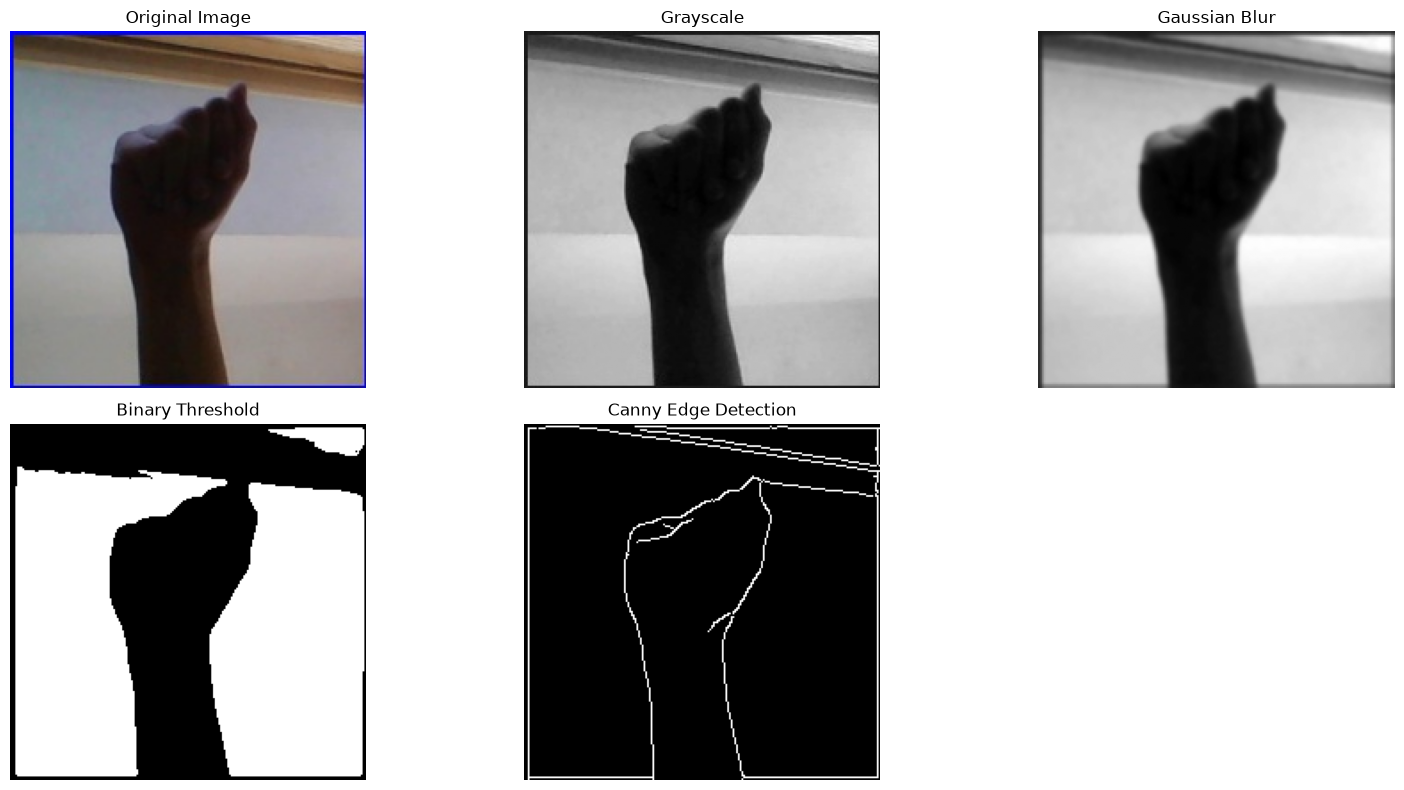

In [4]:
sample_class = "A"
sample_folder = dataset_path / sample_class

sample_images = sorted(file for file in sample_folder.iterdir() if file.is_file() and file.suffix.lower() in image_extensions)

if not sample_images:
    raise FileNotFoundError(f"No images found in {sample_folder}")

image = cv2.imread(str(sample_images[0]))

if image is None:
    raise ValueError("The sample image could not be loaded.")


original = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


blurred = cv2.GaussianBlur(gray, (5, 5), 0)

_, thresholded = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)

edges = cv2.Canny(blurred, 50, 150)


images = [original, gray, blurred, thresholded, edges]

titles = ["Original Image","Grayscale","Gaussian Blur","Binary Threshold","Canny Edge Detection"]

plt.figure(figsize=(16, 8))

for i, (img, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2, 3, i)

    if img.ndim == 2:
        plt.imshow(img, cmap="gray")
    else:
        plt.imshow(img)

    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

### MediaPipe Hands Initialization

Initializing MediaPipe Hands to detect hand landmarks in dataset images.

In [5]:
mp_hands = mp.solutions.hands
mp_drawing = mp.solutions.drawing_utils

hands_static = mp_hands.Hands(static_image_mode=True,max_num_hands=1,min_detection_confidence=0.5)

print("MediaPipe is ready!")

MediaPipe is ready!


### Hand Landmark Feature Extraction

Defining functions to extract the 21 hand landmarks, normalize their coordinates, and convert them into numerical feature vectors.

In [6]:
def extract_hand_features(hand_landmarks):
    coords = np.array([[landmark.x, landmark.y, landmark.z]for landmark in hand_landmarks.landmark],dtype=np.float32)

    # Make the wrist the origin
    coords = coords - coords[0]

    # Normalize the hand size
    scale = np.max(np.abs(coords[:, :2]))

    if scale > 1e-6:
        coords = coords / scale

    return coords.flatten()


def detect_hand_features(image, detector):
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    results = detector.process(rgb_image)

    if results.multi_hand_landmarks:
        return extract_hand_features(results.multi_hand_landmarks[0])

    return None


print("Feature extraction functions are ready!")

Feature extraction functions are ready!


### Feature Extraction from Dataset Images

Processing dataset images, extracting hand landmark features, and preparing the extracted features and labels for machine learning.

In [7]:
MAX_IMAGES_PER_CLASS = 200

x = []
y = []

for class_name in classes:
    class_folder = dataset_path / class_name

    image_files = sorted(file for file in class_folder.iterdir() if file.is_file() and file.suffix.lower() in image_extensions)[:MAX_IMAGES_PER_CLASS]

    successful = 0

    for image_path in image_files:
        image = cv2.imread(str(image_path))

        if image is None:
            continue

        features = detect_hand_features(image, hands_static)

        if features is not None:
            x.append(features)
            y.append(class_name)
            successful += 1

    print(f"{class_name}: {successful}/{len(image_files)} ""images processed successfully")

hands_static.close()

x = np.array(x, dtype=np.float32)
y = np.array(y)

print("\nFeature extraction completed!")
print("x shape:", x.shape)
print("y shape:", y.shape)

A: 182/200 images processed successfully
B: 181/200 images processed successfully
C: 192/200 images processed successfully
D: 197/200 images processed successfully
E: 191/200 images processed successfully
F: 197/200 images processed successfully
G: 182/200 images processed successfully
H: 182/200 images processed successfully
I: 200/200 images processed successfully
J: 149/200 images processed successfully
K: 200/200 images processed successfully
L: 197/200 images processed successfully
M: 101/200 images processed successfully
N: 36/200 images processed successfully
O: 189/200 images processed successfully
P: 198/200 images processed successfully
Q: 194/200 images processed successfully
R: 199/200 images processed successfully
S: 200/200 images processed successfully
T: 183/200 images processed successfully
U: 176/200 images processed successfully
V: 180/200 images processed successfully
W: 118/200 images processed successfully
X: 179/200 images processed successfully
Y: 200/200 images

### Preparing Valid Classes and Labels

Counting the usable samples in each class and identifying classes with insufficient samples for model training.

In [8]:
class_counts = Counter(y)

usable_classes = [class_name for class_name in classes if class_counts.get(class_name, 0) >= 2]

print("Usable classes:", len(usable_classes))
print("Excluded classes:", [class_name for class_name in classes if class_name not in usable_classes])

print("\nSamples per usable class:")
for class_name in usable_classes:
    print(f"{class_name}: {class_counts[class_name]}")

print("\nTotal usable samples:", len(x))

Usable classes: 28
Excluded classes: ['nothing']

Samples per usable class:
A: 182
B: 181
C: 192
D: 197
E: 191
F: 197
G: 182
H: 182
I: 200
J: 149
K: 200
L: 197
M: 101
N: 36
O: 189
P: 198
Q: 194
R: 199
S: 200
T: 183
U: 176
V: 180
W: 118
X: 179
Y: 200
Z: 197
del: 136
space: 176

Total usable samples: 4912


### Splitting Data into Training and Testing Sets

Splitting the valid dataset into training and testing sets while maintaining class proportions through stratified sampling.

In [9]:
valid_mask = np.isin(y, usable_classes)

x_valid = x[valid_mask]
y_valid = y[valid_mask]

x_train, x_test, y_train, y_test = train_test_split(x_valid,y_valid,test_size=0.2,random_state=42,stratify=y_valid)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))
print("Training classes:", len(np.unique(y_train)))

Training samples: 3929
Testing samples: 983
Training classes: 28


### Training the SVM Classifier

Training a Support Vector Machine (SVM) classifier using the extracted hand landmark features to recognize ASL alphabet gestures.

In [10]:
model = SVC(kernel="rbf", C=10, gamma="scale")

model.fit(x_train, y_train)

print("Model training completed!")

Model training completed!


### Model Evaluation and Classification Report

Evaluating the trained model on the test set using accuracy, precision, recall, and F1-score.

In [11]:
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model accuracy: {accuracy:.4f}")
print(f"Model accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(y_test,y_pred,labels=usable_classes,zero_division=0))

Model accuracy: 0.9969
Model accuracy: 99.69%

Classification Report:

              precision    recall  f1-score   support

           A       1.00      1.00      1.00        36
           B       1.00      1.00      1.00        36
           C       1.00      1.00      1.00        38
           D       1.00      1.00      1.00        40
           E       1.00      1.00      1.00        38
           F       1.00      1.00      1.00        40
           G       1.00      1.00      1.00        36
           H       1.00      0.97      0.99        36
           I       1.00      1.00      1.00        40
           J       1.00      1.00      1.00        30
           K       1.00      1.00      1.00        40
           L       1.00      1.00      1.00        40
           M       1.00      1.00      1.00        20
           N       1.00      1.00      1.00         7
           O       1.00      1.00      1.00        38
           P       0.98      1.00      0.99        40
          


### Model Comparison: SVM, KNN, and Random Forest

Comparing three machine learning classifiers using the same training and testing sets. Accuracy, precision, recall, and F1-score are used to evaluate their performance.


In [12]:
comparison_models = {"SVM": SVC(kernel="rbf", C=10, gamma="scale"),"KNN": KNeighborsClassifier(n_neighbors=5),"Random Forest": RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)}

comparison_results = []

for name, estimator in comparison_models.items():


    start_time = time.perf_counter()
    estimator.fit(x_train, y_train)
    training_time = time.perf_counter() - start_time

    start_time = time.perf_counter()
    predictions = estimator.predict(x_test)
    prediction_time = time.perf_counter() - start_time


    comparison_results.append({"Model": name,"Accuracy": accuracy_score(y_test, predictions),"Precision": precision_score(y_test, predictions, average="macro", zero_division=0),"Recall": recall_score(y_test, predictions, average="macro", zero_division=0),"F1-Score": f1_score(y_test, predictions, average="macro", zero_division=0),"Training Time (s)": training_time,"Prediction Time (ms/sample)": (prediction_time / len(x_test)) * 1000})

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4).sort_values(by="Accuracy",ascending=False).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s),Prediction Time (ms/sample)
0,SVM,0.9969,0.9969,0.9966,0.9967,0.0995,0.0890
1,Random Forest,0.9939,0.9933,0.9893,0.9910,0.4022,0.0251
2,KNN,0.9929,0.9917,0.9879,0.9895,0.0016,0.0580


### Model Comparison Visualization

This section visualizes the performance of SVM, KNN, and Random Forest using Accuracy, Precision, Recall, and F1-Score.

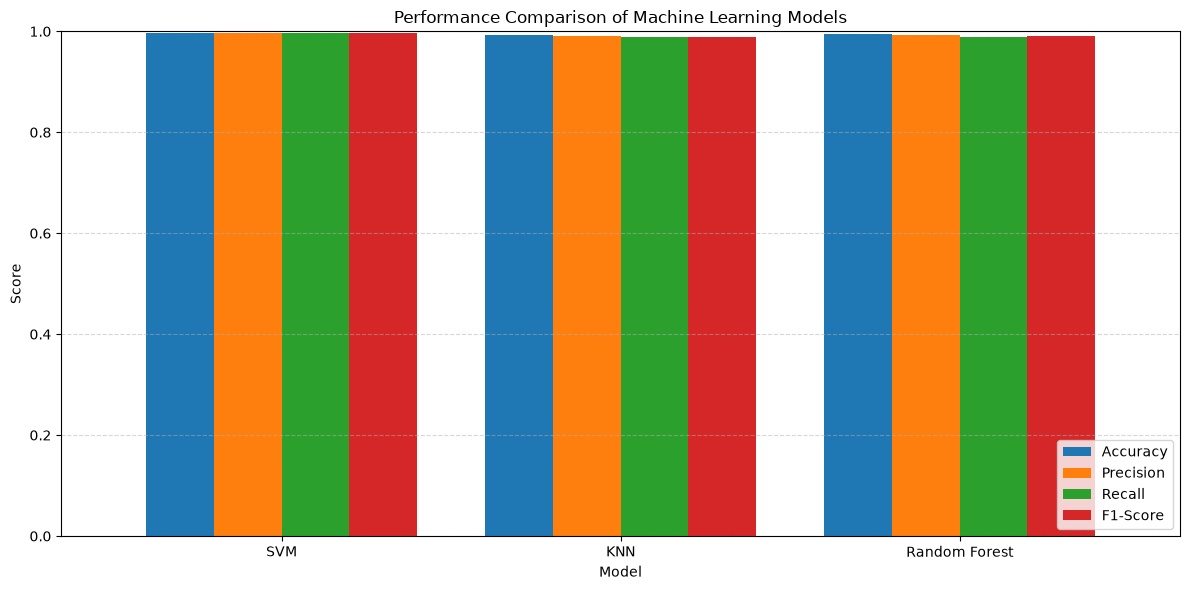

In [13]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

comparison_df.set_index("Model")[metrics].plot(kind="bar",figsize=(12, 6),ylim=(0, 1),width=0.8)

plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### SVM Error Analysis Using Confusion Matrix

The confusion matrix helps identify which ASL alphabet letters are correctly classified and which letters are confused with other classes.

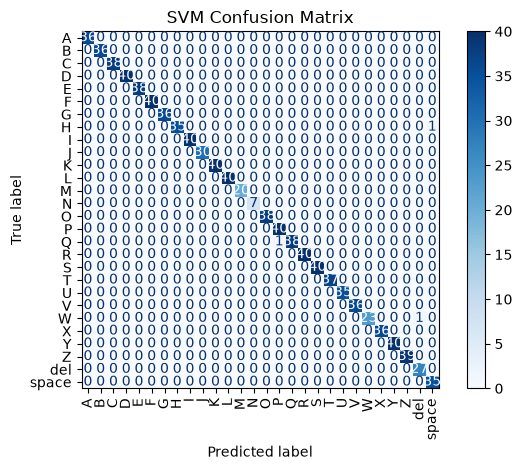

In [14]:
y_pred = model.predict(x_test)

ConfusionMatrixDisplay.from_predictions(y_test,y_pred,xticks_rotation="vertical",cmap="Blues")

plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()

### Classification Error Analysis

This section identifies the most frequently misclassified ASL letters by comparing the true labels with the predicted labels.

In [15]:
cm = confusion_matrix(y_test, y_pred)

labels = model.classes_

error_counts = cm.sum(axis=1) - cm.diagonal()

error_df = pd.DataFrame({
    "Letter": labels,
    "Correct Predictions": cm.diagonal(),
    "Misclassified Predictions": error_counts
})

error_df = error_df.sort_values("Misclassified Predictions",ascending=False)

display(error_df.head(10))

,Letter,Correct Predictions,Misclassified Predictions
22,W,23,1
7,H,35,1
16,Q,38,1
0,A,36,0
15,P,40,0
26,del,27,0
25,Z,39,0
24,Y,40,0
23,X,36,0
21,V,36,0


### Visual Inspection of Model Predictions

In this section, we compare the true labels and predicted labels of sample images to better understand the classification performance of the SVM model.

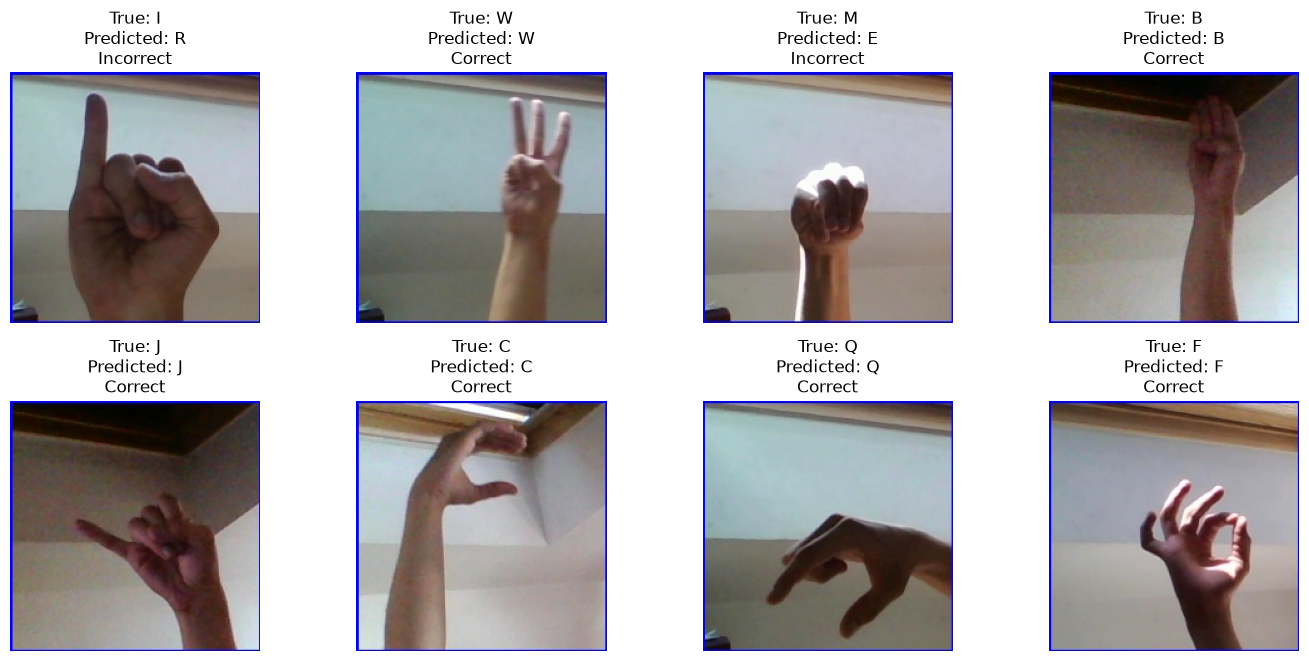

Independent images evaluated: 8
Independent sample accuracy: 75.00%


In [16]:
rng = np.random.default_rng(42)

independent_classes = [class_name for class_name in usable_classes if (dataset_path / class_name).is_dir()]

selected_classes = rng.choice(independent_classes,size=min(12, len(independent_classes)),replace=False)

independent_results = []

hands_independent = mp_hands.Hands(static_image_mode=True,max_num_hands=1,min_detection_confidence=0.5)

try:
    for class_name in selected_classes:
        class_folder = dataset_path / class_name

        image_files = sorted(file for file in class_folder.iterdir() if file.is_file() and file.suffix.lower() in image_extensions)

        # Exclude the first 200 images used in feature extraction
        independent_files = image_files[MAX_IMAGES_PER_CLASS:]

        if not independent_files:
            continue

        image_path = rng.choice(independent_files)
        image_path = Path(image_path)

        image = cv2.imread(str(image_path))

        if image is None:
            continue

        features = detect_hand_features(image,hands_independent)

        if features is None:
            continue

        prediction = model.predict(features.reshape(1, -1))[0]

        independent_results.append({"Image": cv2.cvtColor(image, cv2.COLOR_BGR2RGB),"True Label": class_name,"Predicted Label": prediction,"Correct": class_name == prediction})

finally:
    hands_independent.close()


if independent_results:
    plt.figure(figsize=(14, 10))

    for i, result in enumerate(independent_results):
        plt.subplot(3, 4, i + 1)
        plt.imshow(result["Image"])

        status = ("Correct" if result["Correct"] else "Incorrect")

        plt.title(f"True: {result['True Label']}\n"f"Predicted: {result['Predicted Label']}\n"f"{status}")

        plt.axis("off")

    plt.tight_layout()
    plt.show()

    independent_accuracy = np.mean([result["Correct"] for result in independent_results])

    print("Independent images evaluated:",len(independent_results))
    print(f"Independent sample accuracy: "f"{independent_accuracy:.2%}")

else:
    print(
        "No valid independent hand images were detected. "
        "Check the dataset and MediaPipe detection settings.")


### Saving the Trained Model

In this section, we save the trained SVM model so it can be loaded and reused later without retraining it.

In [17]:
model_path = Path("asl_svm_model.joblib")

joblib.dump(model, model_path)

print(f"Model saved successfully to: {model_path.resolve()}")

Model saved successfully to: C:\Users\SAEED\Desktop\asl_svm_model.joblib


### Loading the Saved Model

The saved model can be loaded later to make predictions on new samples without training the classifier again.

In [18]:
loaded_model = joblib.load("asl_svm_model.joblib")

print("Saved model loaded successfully.")

Saved model loaded successfully.


### Confusion Matrix Visualization

Visualizing the confusion matrix to examine correct predictions and identify misclassifications between ASL classes.

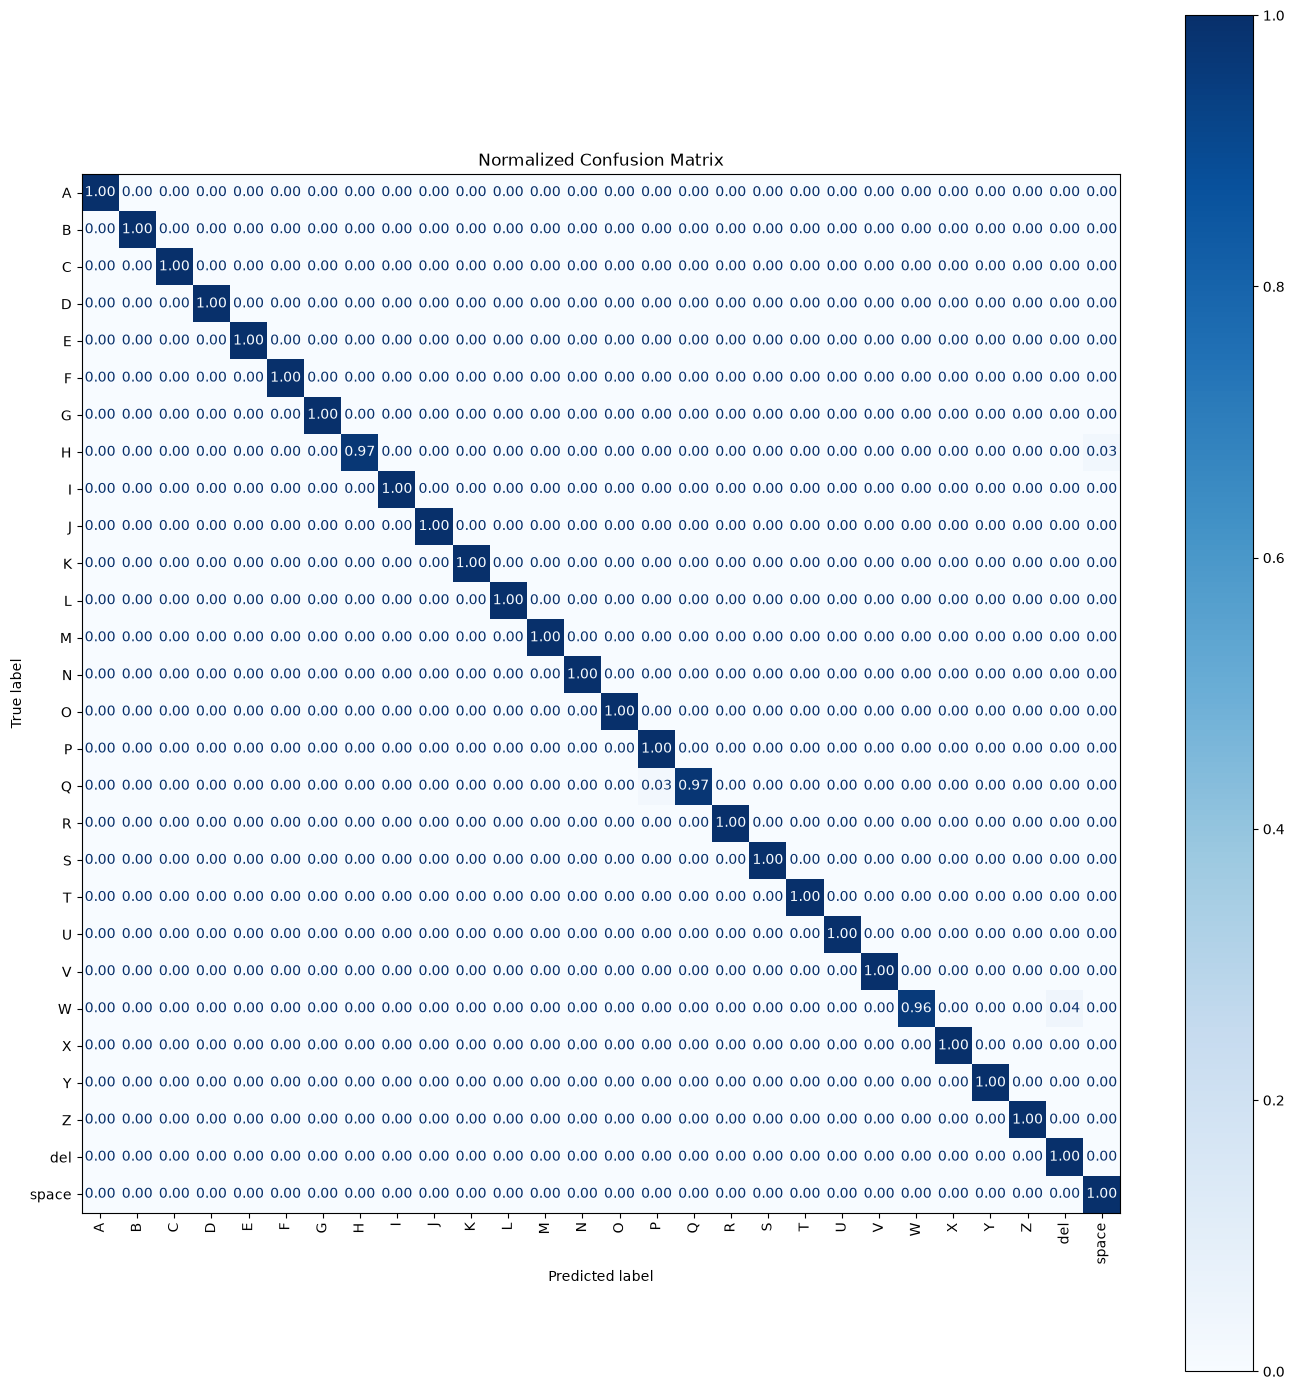

In [19]:
fig, ax = plt.subplots(figsize=(14, 14))

ConfusionMatrixDisplay.from_predictions(y_test,y_pred,labels=usable_classes,xticks_rotation=90,normalize="true",values_format=".2f",cmap="Blues",ax=ax)

plt.title("Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

### Usable Samples per Class

Visualizing the number of usable samples in each class to identify potential class imbalance in the processed dataset.

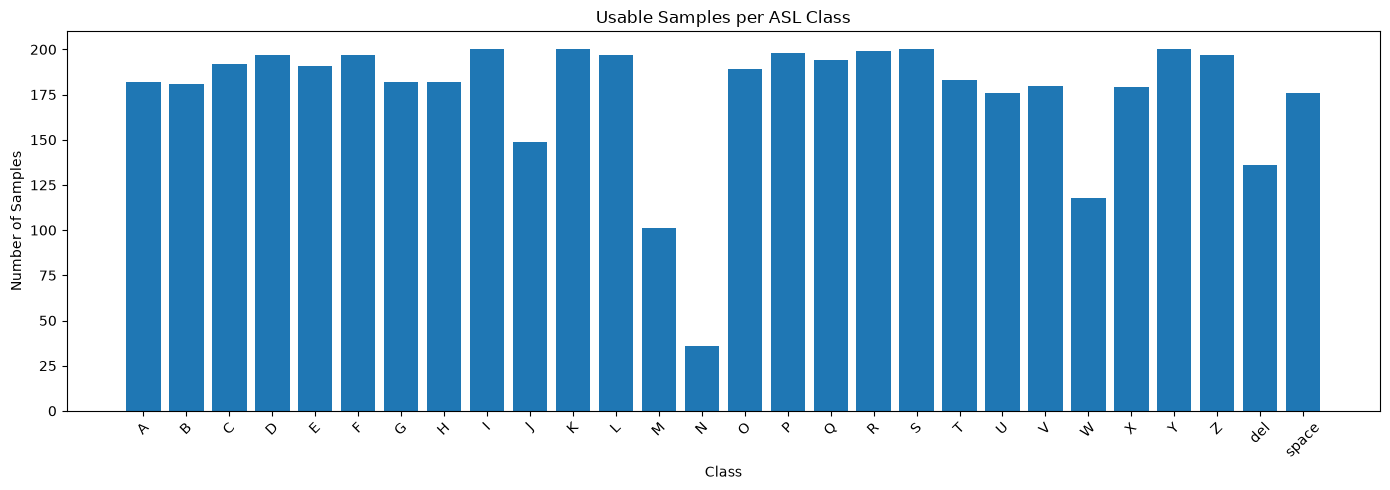

In [20]:
counts = [class_counts[class_name] for class_name in usable_classes]

plt.figure(figsize=(14, 5))
plt.bar(usable_classes, counts)

plt.title("Usable Samples per ASL Class")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Saving the Trained Model

Saving the trained SVM model and its class labels to a Joblib file for later use without retraining the model.

In [21]:
model_path = dataset_path.parent / "asl_svm_model.joblib"

joblib.dump({"model": model,"classes": usable_classes},model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: E:\MFT\VISION\Project\Vision Project\sign\asl_alphabet_train\asl_svm_model.joblib


### Real-Time Hand Detection with Webcam

Testing real-time hand detection using the webcam and displaying the detected hand landmarks.

In [22]:
hands_camera = mp_hands.Hands(static_image_mode=False,max_num_hands=1,min_detection_confidence=0.5,min_tracking_confidence=0.5)

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    hands_camera.close()
    raise RuntimeError("Cannot open webcam. Check camera permissions or camera index.")

print("Press 'q' to close the webcam window.")

try:
    while True:
        ret, frame = cap.read()

        if not ret:
            print("Could not read frame from webcam.")
            break

        frame = cv2.flip(frame, 1)

        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        results = hands_camera.process(rgb_frame)

        if results.multi_hand_landmarks:
            for hand_landmarks in results.multi_hand_landmarks:
                mp_drawing.draw_landmarks(frame,hand_landmarks,mp_hands.HAND_CONNECTIONS)

        cv2.imshow("ASL - Hand Detection Test", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()
    hands_camera.close()

Press 'q' to close the webcam window.


### Real-Time ASL Recognition and Word Builder

Recognizing ASL alphabet gestures from webcam frames, stabilizing predictions, and combining recognized letters to build text.

In [23]:
saved_data = joblib.load(model_path)

model = saved_data["model"]
usable_classes = saved_data["classes"]

hands_camera = mp_hands.Hands(static_image_mode=False,max_num_hands=1,min_detection_confidence=0.5,min_tracking_confidence=0.5)

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    hands_camera.close()
    raise RuntimeError("Cannot open webcam. Check camera permissions or camera index.")

print("Live ASL recognition started. Press 'q' to quit.")

try:
    while True:
        ret, frame = cap.read()

        if not ret:
            print("Could not read frame from webcam.")
            break

        frame = cv2.flip(frame, 1)
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        results = hands_camera.process(rgb_frame)

        prediction_text = "Show your hand"

        if results.multi_hand_landmarks:
            hand_landmarks = results.multi_hand_landmarks[0]

            mp_drawing.draw_landmarks(frame,hand_landmarks,mp_hands.HAND_CONNECTIONS)

            features = extract_hand_features(hand_landmarks)

            prediction = model.predict(features.reshape(1, -1))[0]

            prediction_text = f"Prediction: {prediction}"

        cv2.putText(frame,prediction_text,(20, 50),cv2.FONT_HERSHEY_SIMPLEX,1,(0, 255, 0),2,cv2.LINE_AA)

        cv2.imshow("Live ASL Recognition", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()
    hands_camera.close()

Live ASL recognition started. Press 'q' to quit.


### Two-Hand Detection Test

Testing MediaPipe's ability to detect and display landmarks for two hands simultaneously using the webcam.

In [24]:
hands_camera = mp_hands.Hands(static_image_mode=False,max_num_hands=2,min_detection_confidence=0.5,min_tracking_confidence=0.5)

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    hands_camera.close()
    raise RuntimeError("Cannot open webcam.")

try:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        frame = cv2.flip(frame, 1)
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        results = hands_camera.process(rgb)

        hand_count = 0

        if results.multi_hand_landmarks:
            hand_count = len(results.multi_hand_landmarks)

            for landmarks in results.multi_hand_landmarks:
                mp_drawing.draw_landmarks(frame,landmarks,mp_hands.HAND_CONNECTIONS)

        cv2.putText(frame,f"Hands detected: {hand_count}",(20, 40),cv2.FONT_HERSHEY_SIMPLEX,1,(0, 255, 0),2)

        cv2.imshow("Two-Hand Detection", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()
    hands_camera.close()

### Live Word Formation and Keyboard Controls

Testing live word formation and keyboard controls for adding letters, inserting spaces, deleting characters, clearing text, and exiting the application.

In [25]:
from collections import deque

saved_data = joblib.load(model_path)
model = saved_data["model"]

hands_camera = mp_hands.Hands(static_image_mode=False,max_num_hands=2,min_detection_confidence=0.5,min_tracking_confidence=0.5)

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    hands_camera.close()
    raise RuntimeError("Cannot open webcam.")

recognized_text = ""
recent_predictions = deque(maxlen=12)
last_added = None
no_hand_frames = 0

print("Live ASL word builder started.")
print("Enter: space | Backspace: delete | C: clear | Q: quit")

try:
    while True:
        ret, frame = cap.read()

        if not ret:
            break

        frame = cv2.flip(frame, 1)
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        results = hands_camera.process(rgb)

        current_prediction = None

        if results.multi_hand_landmarks:
            no_hand_frames = 0


            for landmarks in results.multi_hand_landmarks:
                mp_drawing.draw_landmarks(frame,landmarks,mp_hands.HAND_CONNECTIONS)



            landmarks = results.multi_hand_landmarks[0]
            features = extract_hand_features(landmarks)

            current_prediction = model.predict(features.reshape(1, -1))[0]

            recent_predictions.append(current_prediction)


            if (len(recent_predictions) == recent_predictions.maxlen and len(set(recent_predictions)) == 1):
                stable_letter = recent_predictions[0]

                if stable_letter != last_added:
                    recognized_text += stable_letter
                    last_added = stable_letter

        else:
            recent_predictions.clear()
            no_hand_frames += 1



            if no_hand_frames >= 10:
                last_added = None

        prediction_label = (f"Prediction: {current_prediction}" if current_prediction is not None else "Show your hand")

        cv2.putText(frame,prediction_label,(20, 35),cv2.FONT_HERSHEY_SIMPLEX,0.8,(0, 255, 0),2)


        cv2.rectangle(frame, (10, 55), (frame.shape[1] - 10, 110),(30, 30, 30), -1)

        display_text = recognized_text[-45:] or "(empty)"

        cv2.putText(frame,"Text: " + display_text,(20, 90),cv2.FONT_HERSHEY_SIMPLEX,0.8,(255, 255, 255),2)

        cv2.imshow("ASL Word Builder", frame)

        key = cv2.waitKey(1) & 0xFF

        if key == ord("q"):
            break
        elif key in (13, 10): 
            recognized_text += " "
            last_added = None
            recent_predictions.clear()
        elif key in (8, 127):  # Backspace
            recognized_text = recognized_text[:-1]
            last_added = None
            recent_predictions.clear()
        elif key == ord("c"):
            recognized_text = ""
            last_added = None
            recent_predictions.clear()

finally:
    cap.release()
    cv2.destroyAllWindows()
    hands_camera.close()

print("Final text:", recognized_text)

Live ASL word builder started.
Enter: space | Backspace: delete | C: clear | Q: quit
Final text: B


# Conclusion

## Project Summary

In this project, a real-time American Sign Language (ASL) alphabet recognition system was developed using Python, MediaPipe, OpenCV, and a Support Vector Machine (SVM) classifier.

The system extracts hand landmarks from images and webcam frames, converts them into numerical features, and uses the trained SVM model to classify hand gestures. The recognized letters can be combined to form words through an interactive interface.

## Results

- **Dataset:** ASL alphabet dataset containing 29 original classes.
- **Feature Extraction:** MediaPipe hand landmarks based on 21 key points per hand.
- **Classification Model:** Support Vector Machine (SVM) with an RBF kernel.
- **Usable Samples:** 4,912 extracted samples.
- **Test Accuracy:** 99.69% on the held-out test set.
- **Real-Time Recognition:** Webcam-based hand detection and letter recognition were implemented, along with an interactive word-building feature.

## Limitations

The current system primarily recognizes static hand gestures using features extracted from a single hand. Although recognized letters can be combined to form words, the system does not perform complete continuous sign language translation.

Some ASL letters, such as J and Z, involve movement and may require temporal information for reliable recognition. The `nothing` class was excluded from model training because no usable hand landmark samples were extracted for it.

Additionally, the reported test accuracy reflects performance on the prepared test set and does not guarantee the same level of accuracy under all real-world conditions.

## Future Improvements

Potential improvements include:

- Incorporating temporal models, such as LSTM or Transformer-based architectures, to recognize movement-based signs.
- Improving support for two-handed gestures.
- Enhancing recognition under different lighting conditions, backgrounds, and camera angles.
- Collecting more diverse training data and evaluating performance on independent real-world recordings.
- Extending the system toward continuous sign recognition and sentence-level translation.

## Final Conclusion

This project demonstrates how computer vision and machine learning can be combined to develop a real-time ASL alphabet recognition system. By integrating hand landmark extraction, machine learning classification, and webcam-based interaction, the project provides a foundation for further development toward more advanced sign language recognition applications.